In [48]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import librosa

In [49]:
df = pd.read_csv("my_gtzan_features.csv")
df.head()

,tempo,spectral_centroid_mean,spectral_centroid_std,spectral_rolloff_mean,spectral_rolloff_std,zero_crossing_rate_mean,zero_crossing_rate_std,rms_mean,rms_std,chroma_stft_mean,...,mfcc_11_std,mfcc_12_mean,mfcc_12_std,perceptr_std,perceptr_mean,harmony_mean,harmony_std,length,nom_fichier,genre
0,123.046875,1784.416546,360.194166,3806.418650,949.383832,0.083066,0.027690,0.130192,0.053201,0.349951,...,7.161843,-3.665802,6.422743,0.075527,0.000007,-0.000045,0.090398,30.0,blues.00000.wav,blues
1,67.999589,1529.871314,613.197888,3548.986873,1725.338349,0.056044,0.038059,0.095892,0.048724,0.340945,...,9.813216,-2.237833,8.056108,0.055377,-0.000181,0.000142,0.071392,30.0,blues.00001.wav,blues
2,161.499023,1552.637786,395.649207,3041.089944,884.842654,0.076301,0.031738,0.175494,0.052465,0.363562,...,8.037509,-8.899733,7.776661,0.086383,-0.000016,0.000001,0.127867,30.0,blues.00002.wav,blues
3,63.024009,1070.110059,429.542379,2185.061787,1222.372310,0.033309,0.020569,0.141139,0.079623,0.404848,...,6.941436,-2.476188,7.537466,0.052084,-0.000018,0.000004,0.138070,30.0,blues.00003.wav,blues
4,135.999178,1835.507008,585.947299,3581.003346,1253.847208,0.101500,0.044199,0.091540,0.048011,0.308598,...,9.300109,-6.935621,9.466440,0.055630,-0.000010,-0.000018,0.069409,30.0,blues.00004.wav,blues


In [50]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 44 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   tempo                    1000 non-null   float64
 1   spectral_centroid_mean   1000 non-null   float64
 2   spectral_centroid_std    1000 non-null   float64
 3   spectral_rolloff_mean    1000 non-null   float64
 4   spectral_rolloff_std     1000 non-null   float64
 5   zero_crossing_rate_mean  1000 non-null   float64
 6   zero_crossing_rate_std   1000 non-null   float64
 7   rms_mean                 1000 non-null   float64
 8   rms_std                  1000 non-null   float64
 9   chroma_stft_mean         1000 non-null   float64
 10  chroma_stft_std          1000 non-null   float64
 11  spectral_bandwidth_mean  1000 non-null   float64
 12  spectral_bandwidth_std   1000 non-null   float64
 13  mfcc_1_mean              1000 non-null   float64
 14  mfcc_1_std               1000 non-nu

In [51]:

df.describe()

,tempo,spectral_centroid_mean,spectral_centroid_std,spectral_rolloff_mean,spectral_rolloff_std,zero_crossing_rate_mean,zero_crossing_rate_std,rms_mean,rms_std,chroma_stft_mean,...,mfcc_10_std,mfcc_11_mean,mfcc_11_std,mfcc_12_mean,mfcc_12_std,perceptr_std,perceptr_mean,harmony_mean,harmony_std,length
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,...,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,119.424661,2201.908469,631.584890,4571.877792,1264.469454,0.103637,0.049371,0.130875,0.048339,0.378696,...,8.482878,4.471887,8.094807,-4.798732,8.038716,0.063977,-0.000396,-0.000366,0.101017,29.999879
std,28.224072,715.936438,266.035677,1574.686981,495.119974,0.041834,0.023437,0.065659,0.026738,0.081704,...,1.885959,6.717816,1.766198,6.171305,1.796280,0.039745,0.001082,0.001684,0.048392,0.002266
min,58.726918,570.150688,89.206350,749.528801,121.686233,0.021701,0.006633,0.005270,0.002069,0.171770,...,4.627245,-15.806172,4.320407,-27.549044,4.157429,0.000914,-0.007154,-0.026058,0.007032,29.931973
25%,99.384014,1628.001256,429.714464,3381.008722,879.415198,0.070281,0.032848,0.086586,0.030665,0.319462,...,7.152777,-0.551719,6.846061,-9.365386,6.799285,0.035958,-0.000534,-0.000106,0.066220,30.000000
50%,117.453835,2209.457924,581.958628,4658.484331,1215.082615,0.099539,0.044973,0.122397,0.042690,0.383055,...,8.275759,3.889783,7.878847,-4.200263,7.811946,0.058400,-0.000036,-0.000004,0.093633,30.000000
75%,135.999178,2691.943500,782.453792,5534.110286,1598.693138,0.132007,0.060247,0.175723,0.059856,0.435605,...,9.547414,9.707966,9.067629,-0.157045,8.929124,0.087327,-0.000004,0.000002,0.130183,30.000000
max,234.907670,4434.948743,1742.272546,8676.447535,2942.959745,0.274829,0.169380,0.397851,0.166458,0.663541,...,24.301636,23.026806,17.253351,13.060921,17.016661,0.217270,0.005789,0.015053,0.292677,30.000000


In [52]:
print('Différents genres :')
print(list(df["genre"].unique()))

Différents genres :
['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']


#                                 Analyse exploratoire



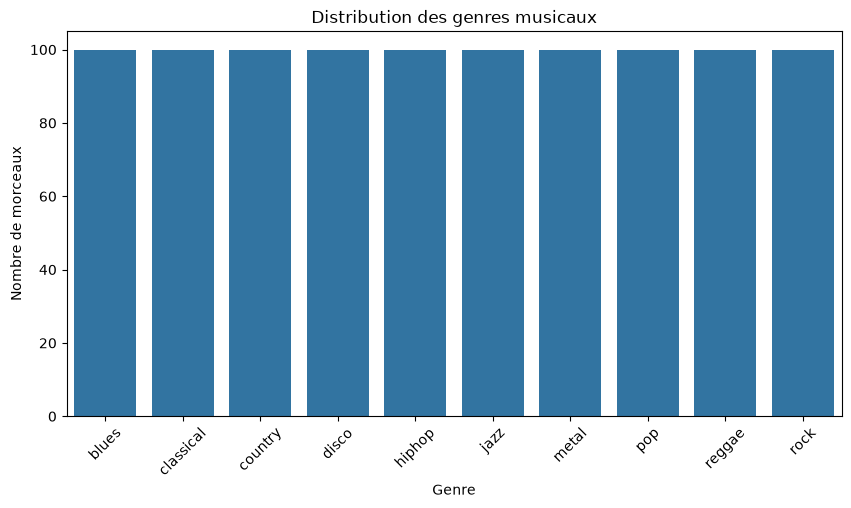

In [53]:
#distribution du genre
plt.figure(figsize=(10,5))
sns.countplot(x="genre",data=df,order=df["genre"].value_counts().index)
plt.title("Distribution des genres musicaux")
plt.xlabel("Genre")
plt.ylabel("Nombre de morceaux")
plt.xticks(rotation=45)
plt.show()

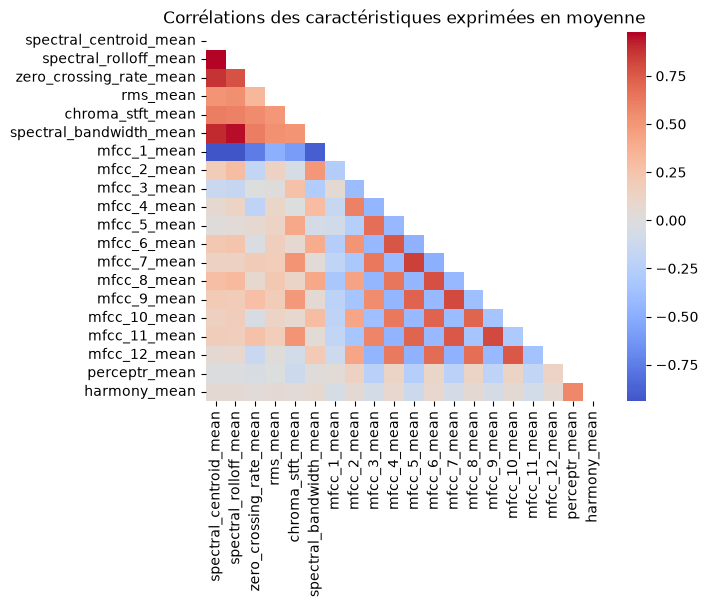

In [54]:
# corrélation des descripteurs 
mean_cols = [col for col in df.columns if "_mean" in col]
corr_mean = df[mean_cols].corr()
plt.title("Corrélations des caractéristiques exprimées en moyenne")
mask_vis = np.triu(np.ones_like(corr_mean, dtype=bool))
sns.heatmap(corr_mean, mask=mask_vis, cmap="coolwarm", center=0)
plt.show()

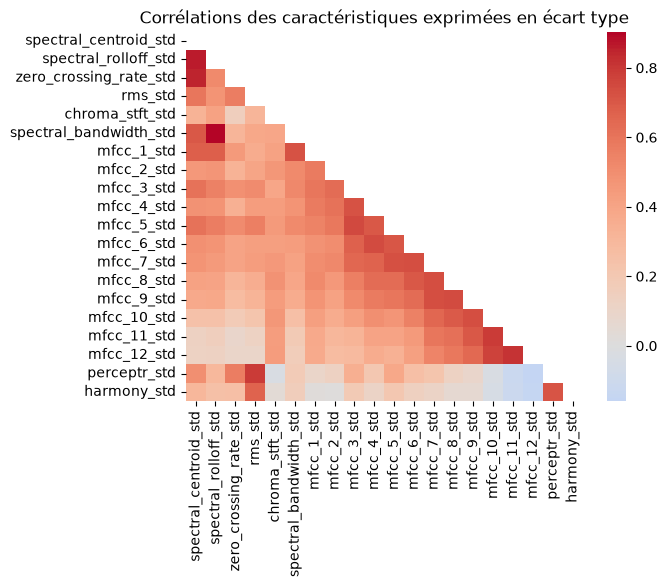

In [55]:
# corrélation des descripteurs 
std_cols = [col for col in df.columns if "_std" in col]
corr_std = df[std_cols].corr()
plt.title("Corrélations des caractéristiques exprimées en écart type")
mask_vis = np.triu(np.ones_like(corr_std, dtype=bool))
sns.heatmap(corr_std, mask=mask_vis, cmap="coolwarm", center=0)
plt.show()

Ces matrices de corrélation mettent en évidence plusieurs paires de variables fortement `corrélées`.
Cette observation révèle une certaine `redondance` de l'information contenue dans les caractéristiques audio extraites.
En effet, les corrélations élevées observées suggèrent que certaines variables capturent des aspects `similaires`,voire très proches, du signal musical. Cette redondance est particulièrement visible parmi certaines caractéristiques
spectrales et `coefficients MFCC`, qui décrivent des propriétés fréquentielles apparentées.
À l'inverse, de nombreuses variables présentent des corrélations faibles ou modérées,ce qui indique qu'elles
apportent des informations complémentaires et potentiellement utiles à la discrimination des genres musicaux.


In [56]:
# comportement du genre en fonc  tion des caractéristiques
# boxplot
def boxplot(variable_x,variable_y,data):
    plt.figure(figsize=(12,6))
    sns.boxplot(x=variable_x,y=variable_y,data=data,palette='husl')
    plt.xticks(rotation=45)
    plt.title(f"Boxplot de {variable_y} selon {variable_x}",fontsize=15,fontweight="bold")
    plt.xticks(fontsize = 14)
    plt.yticks(fontsize = 10)
    plt.xlabel(variable_x,fontsize=15)
    plt.ylabel(variable_y,fontsize=15)
    plt.show()

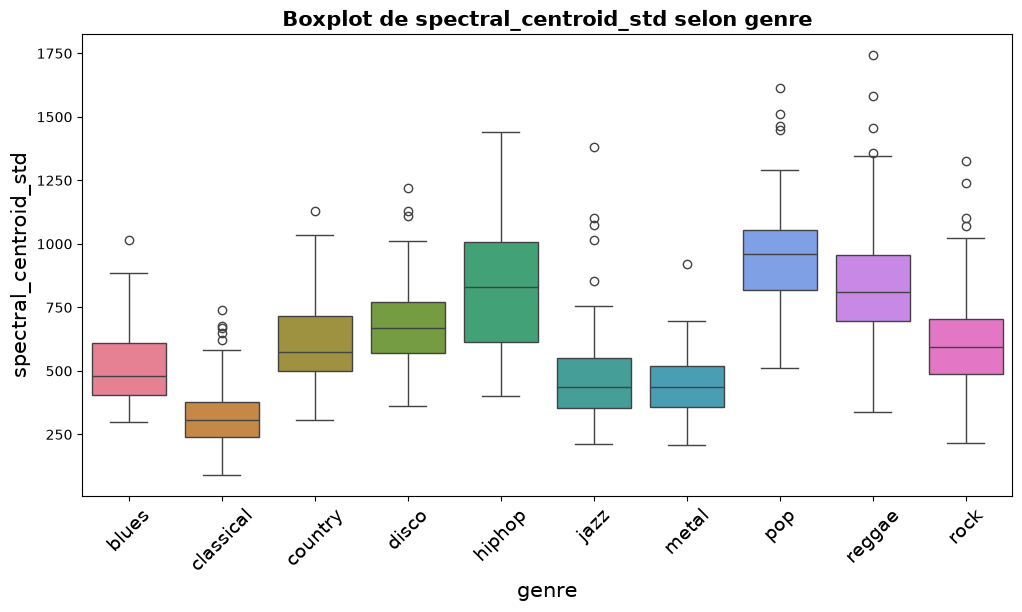

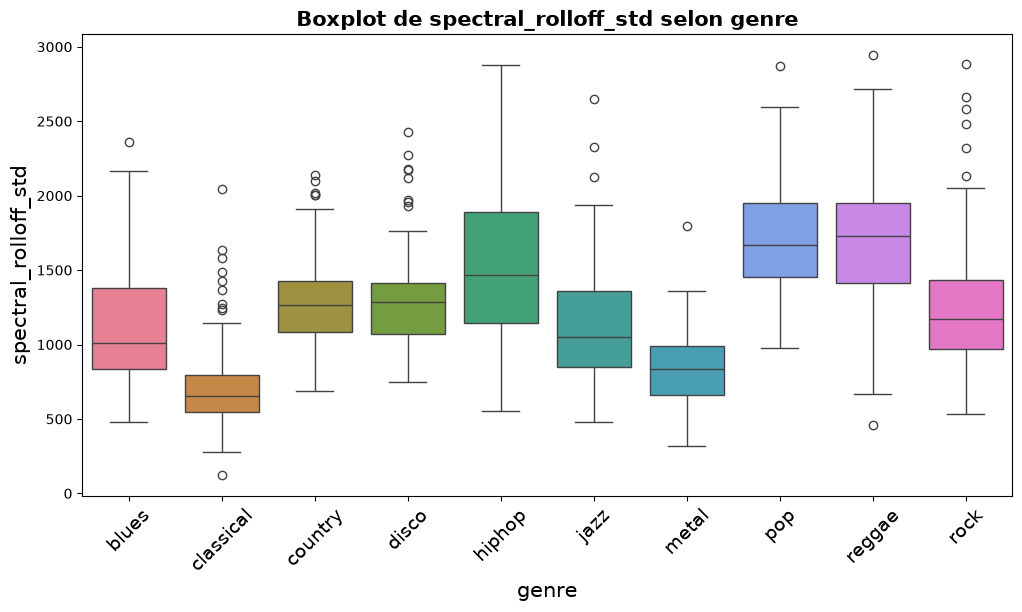

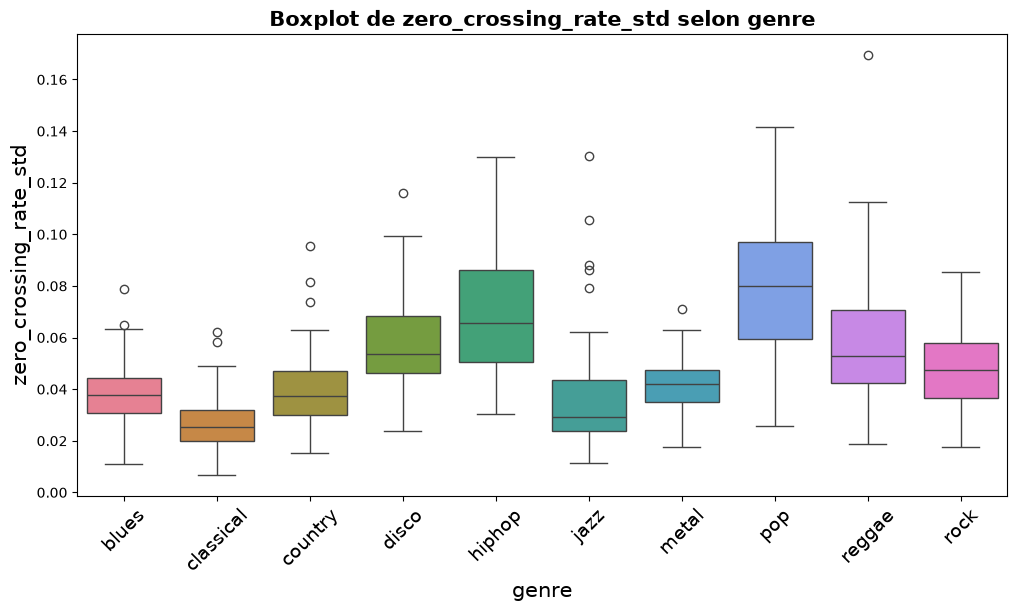

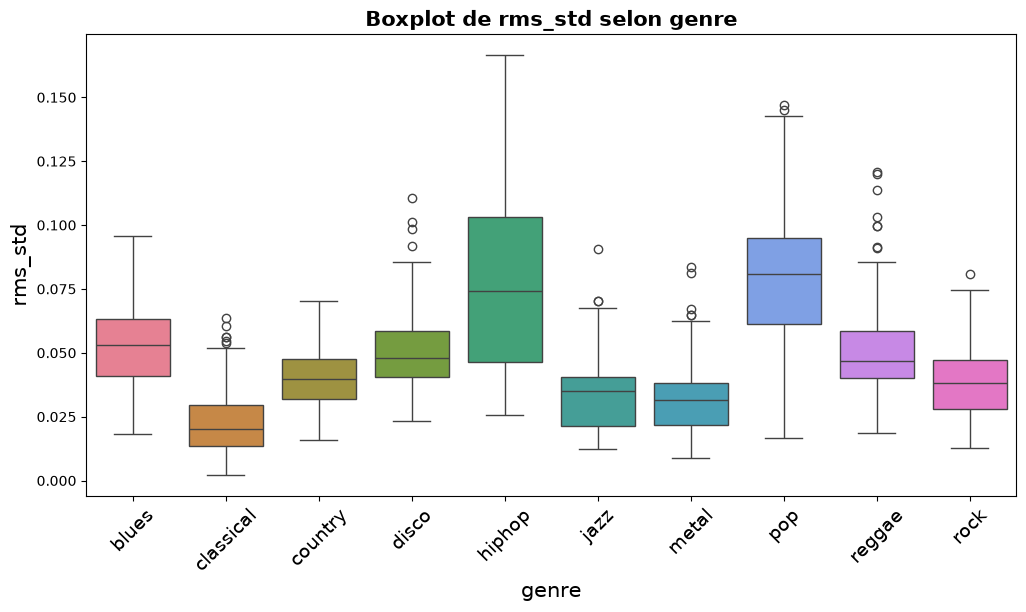

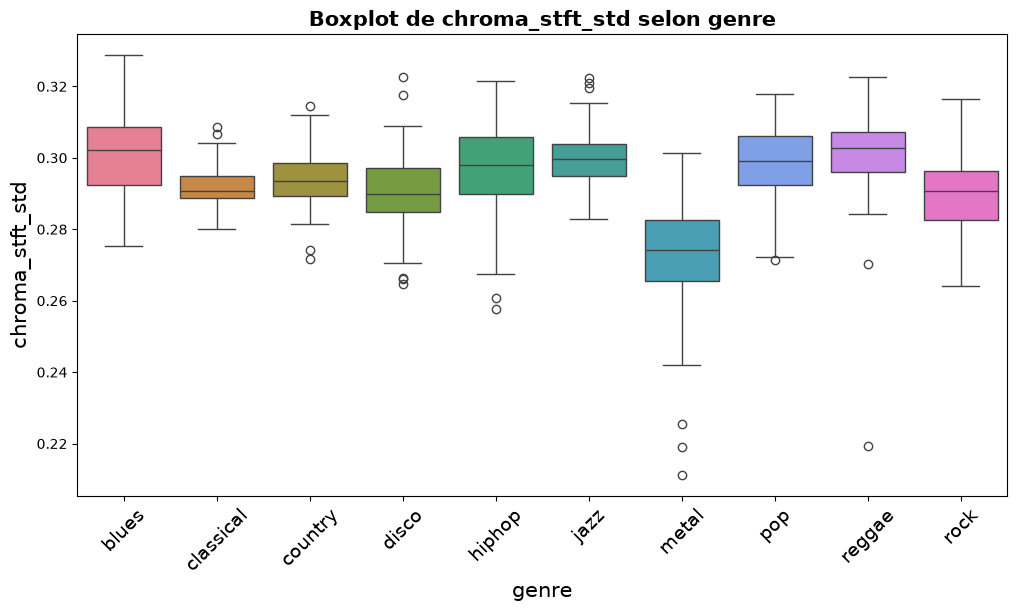

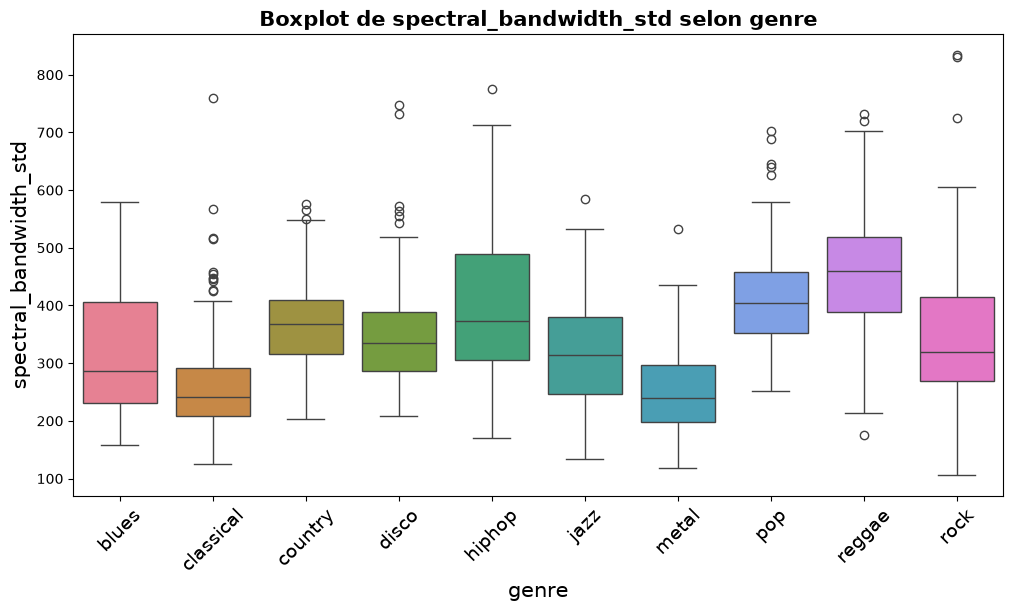

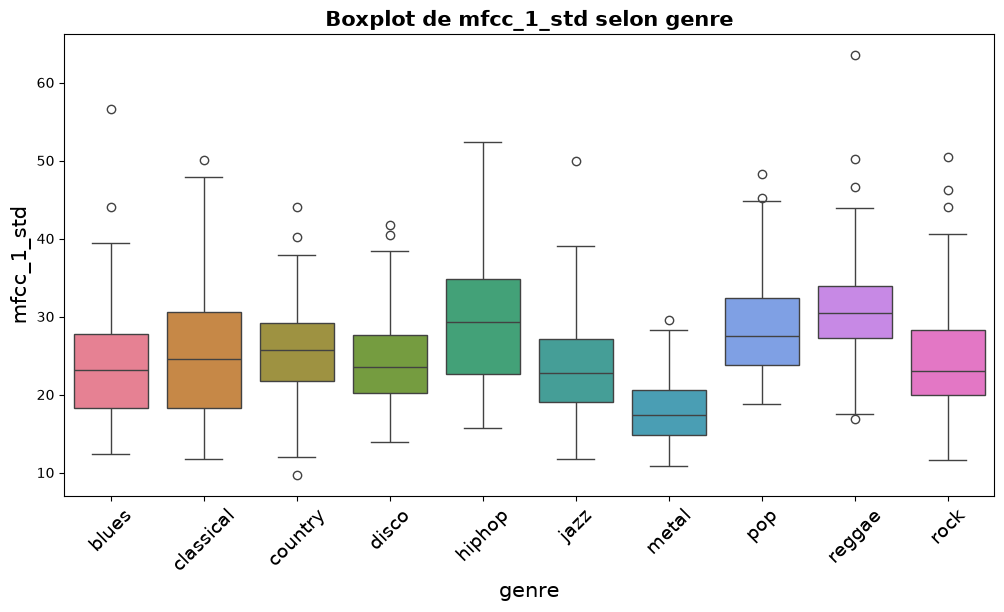

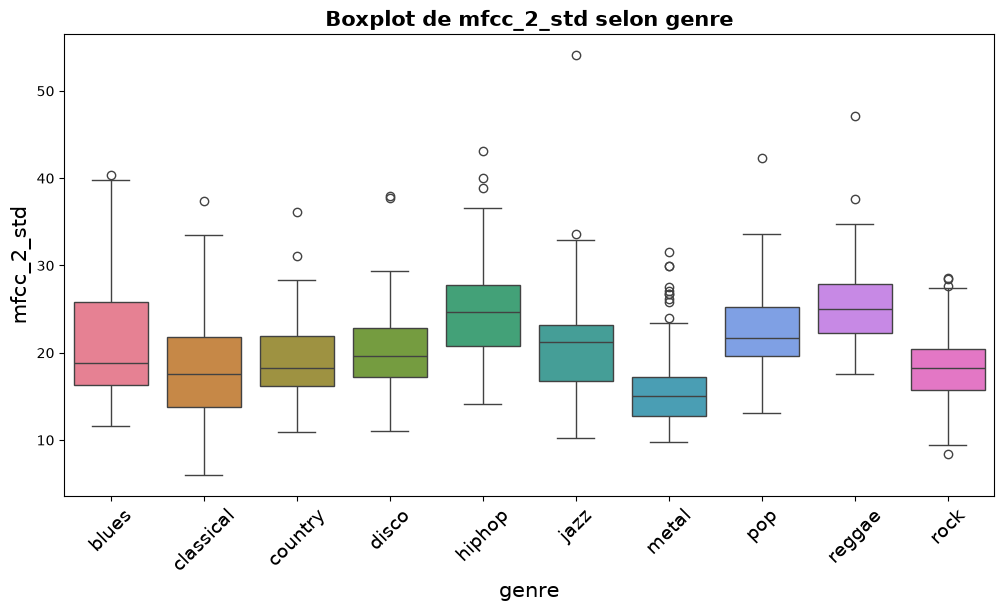

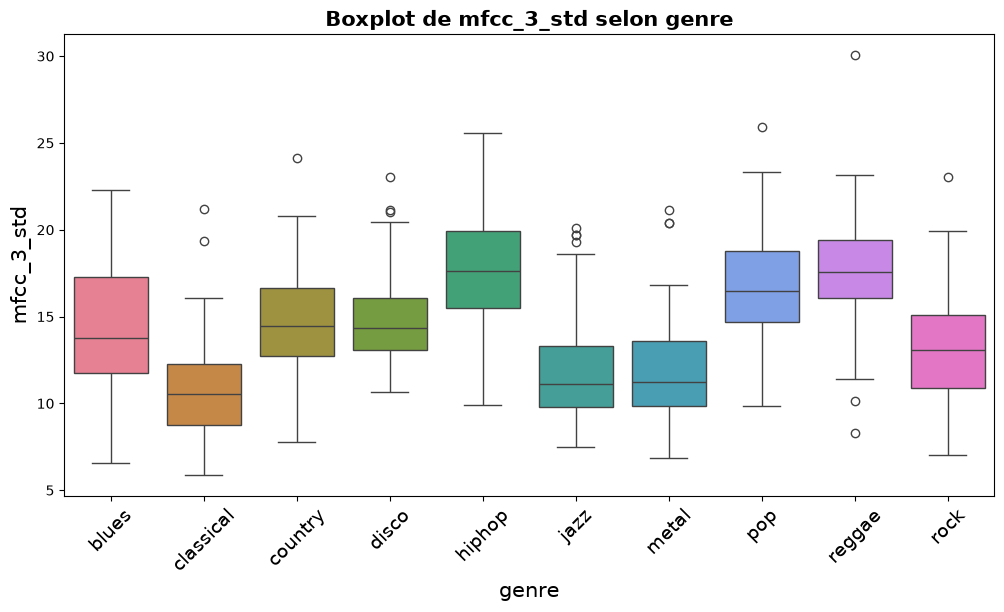

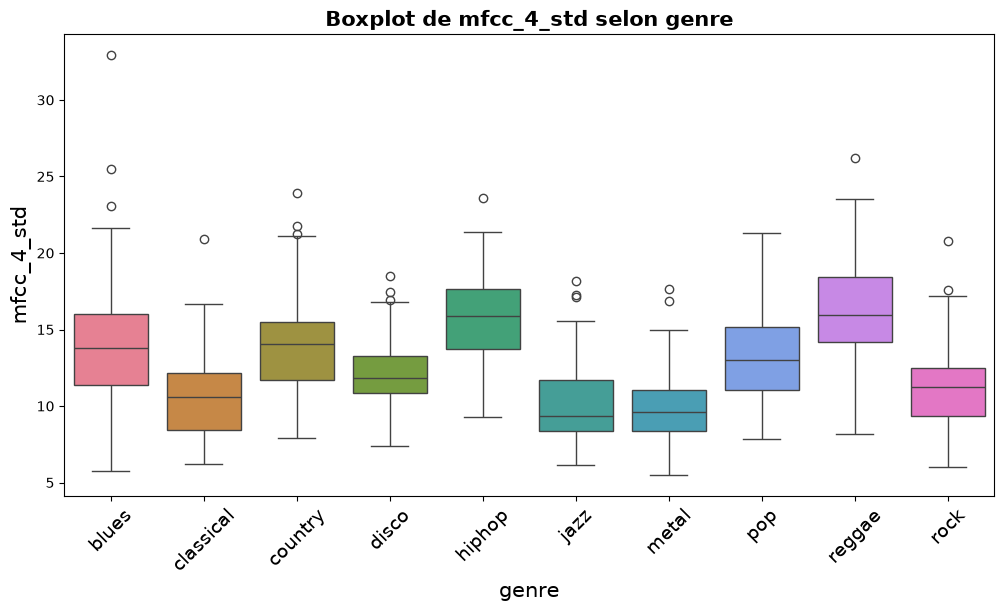

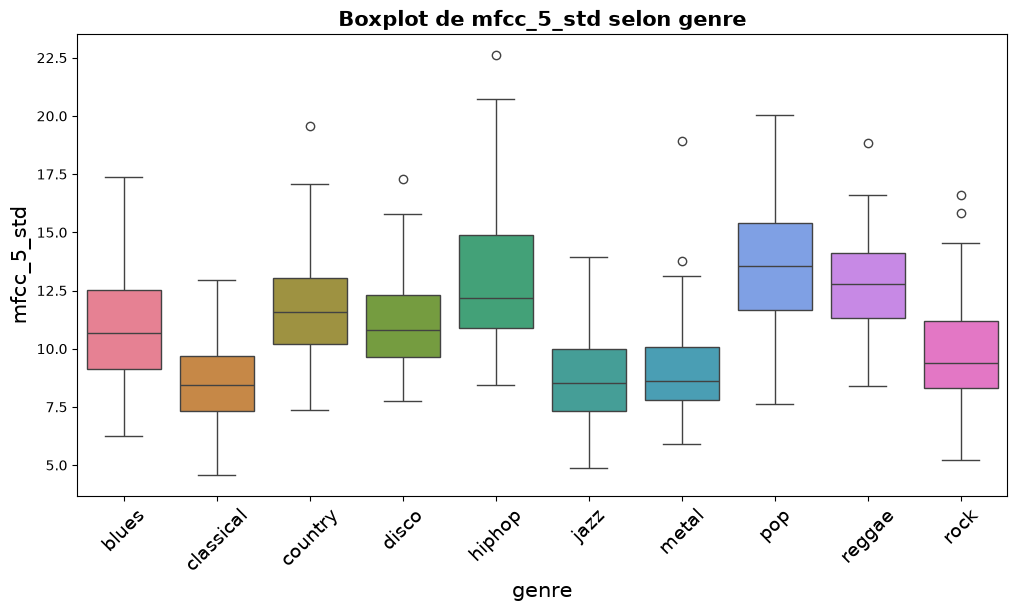

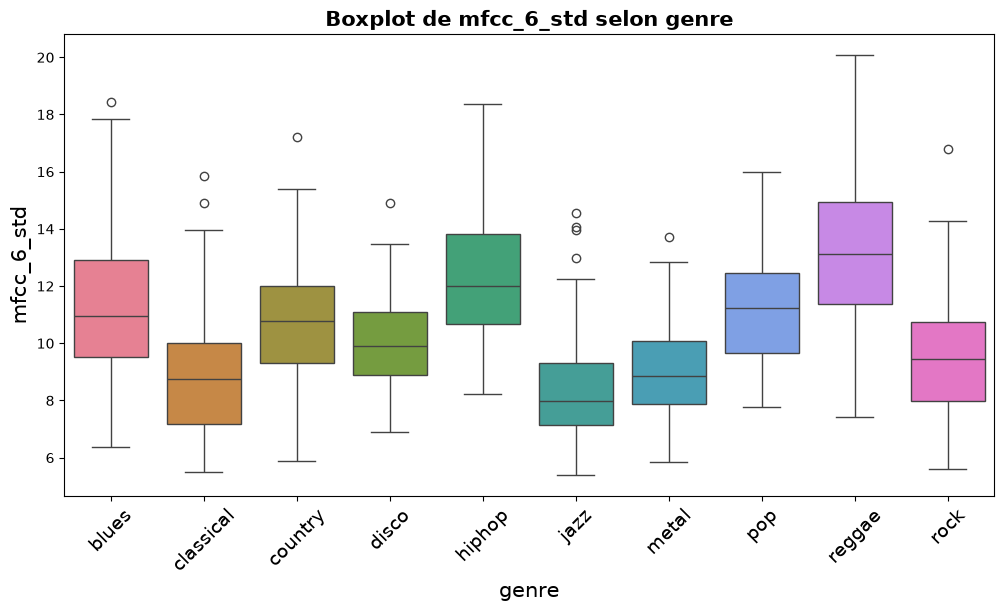

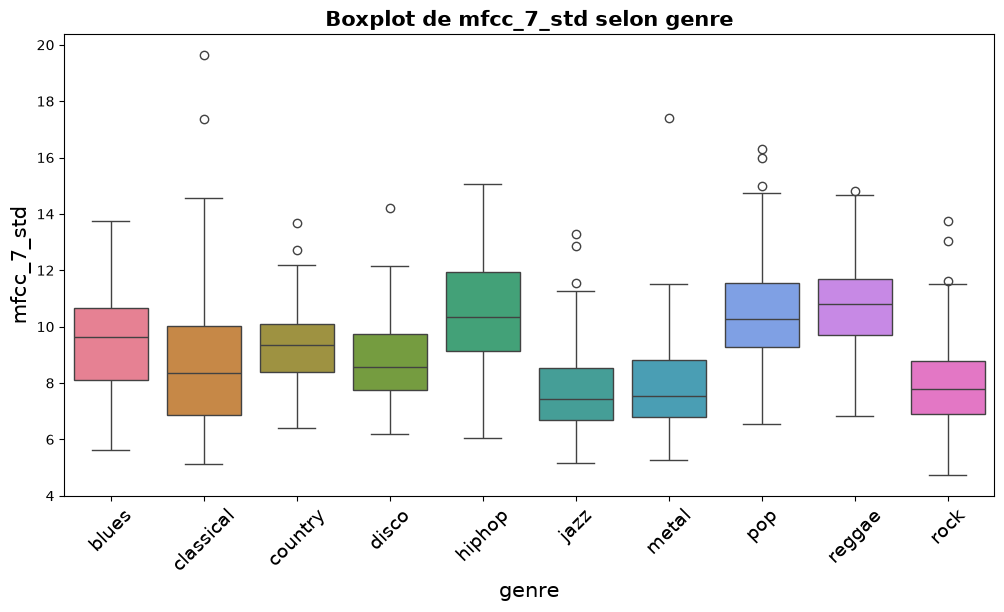

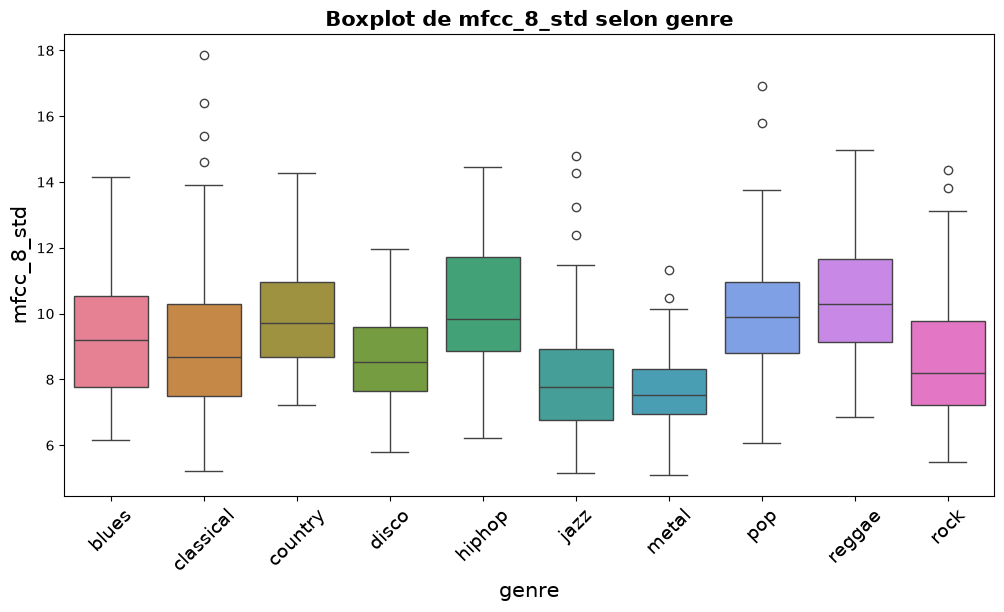

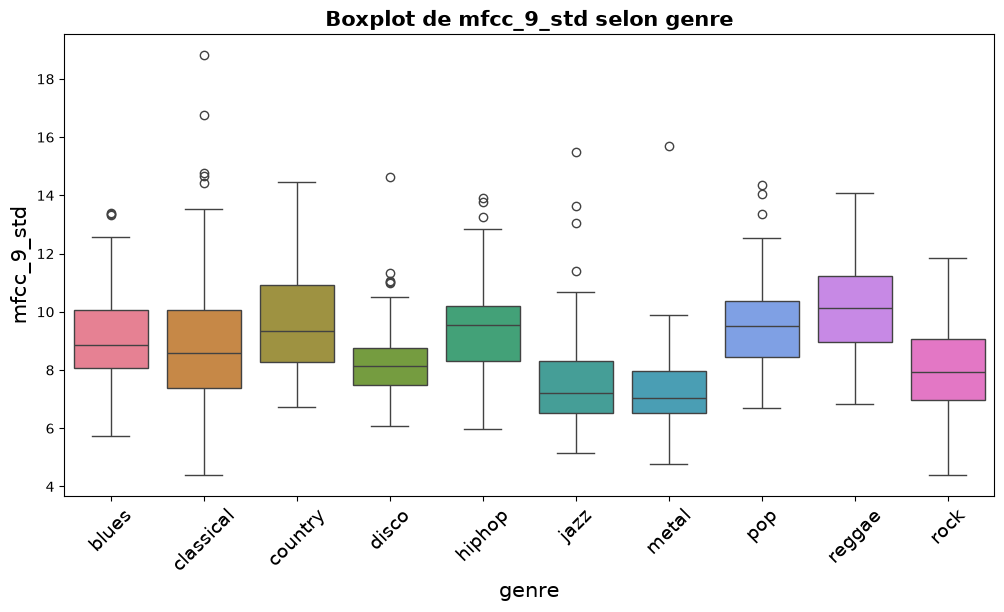

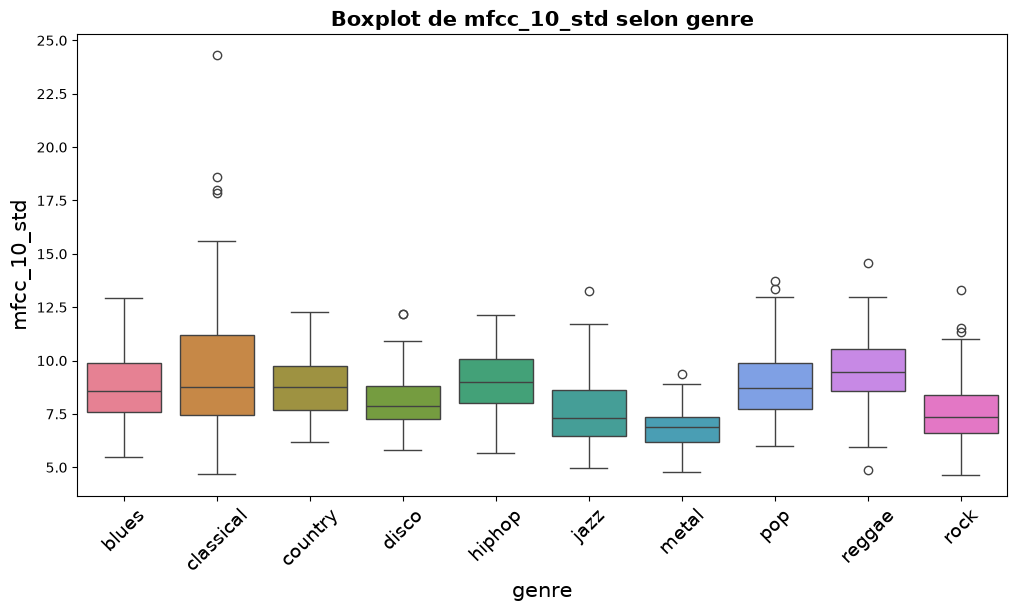

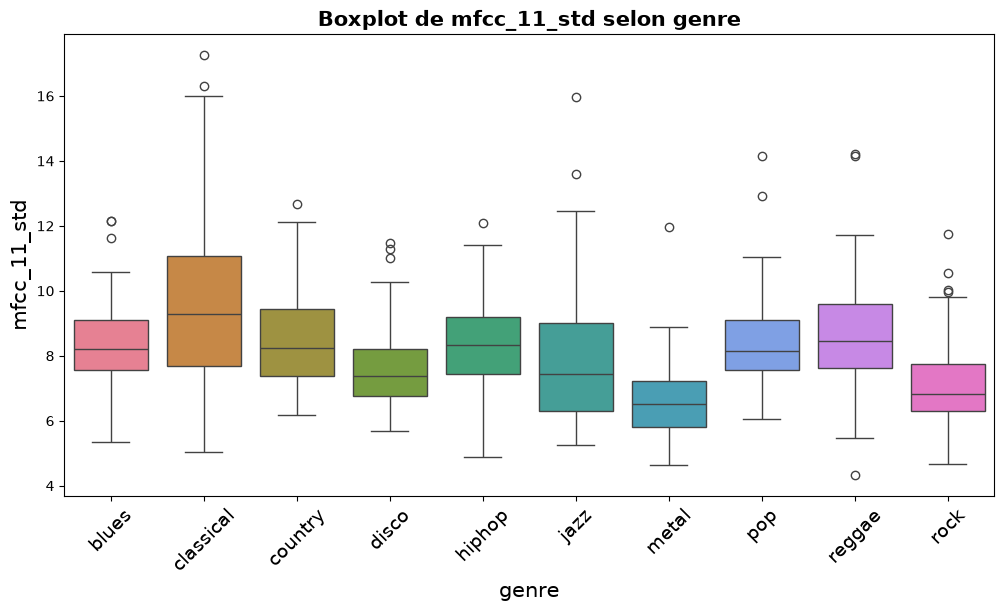

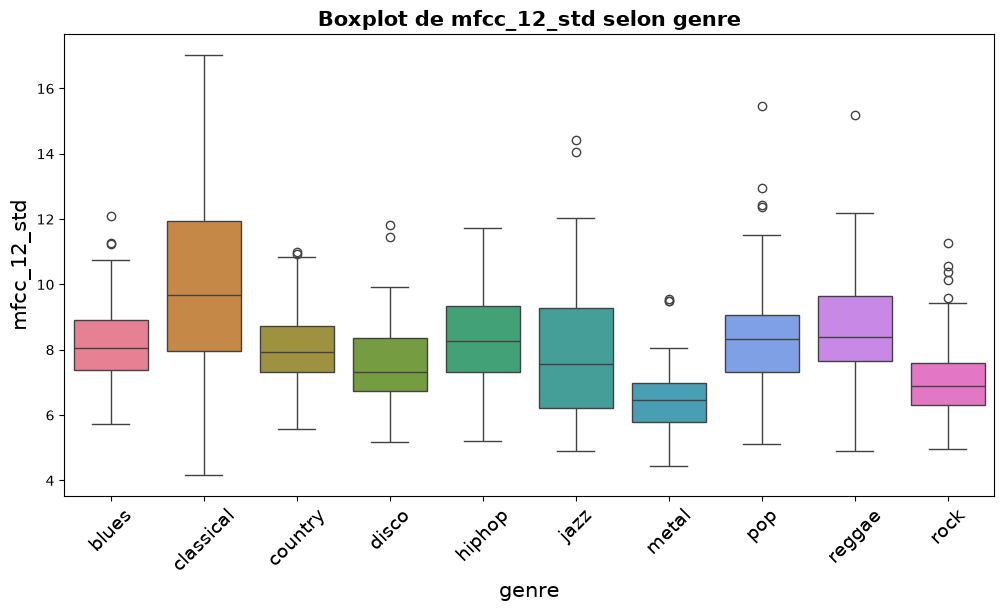

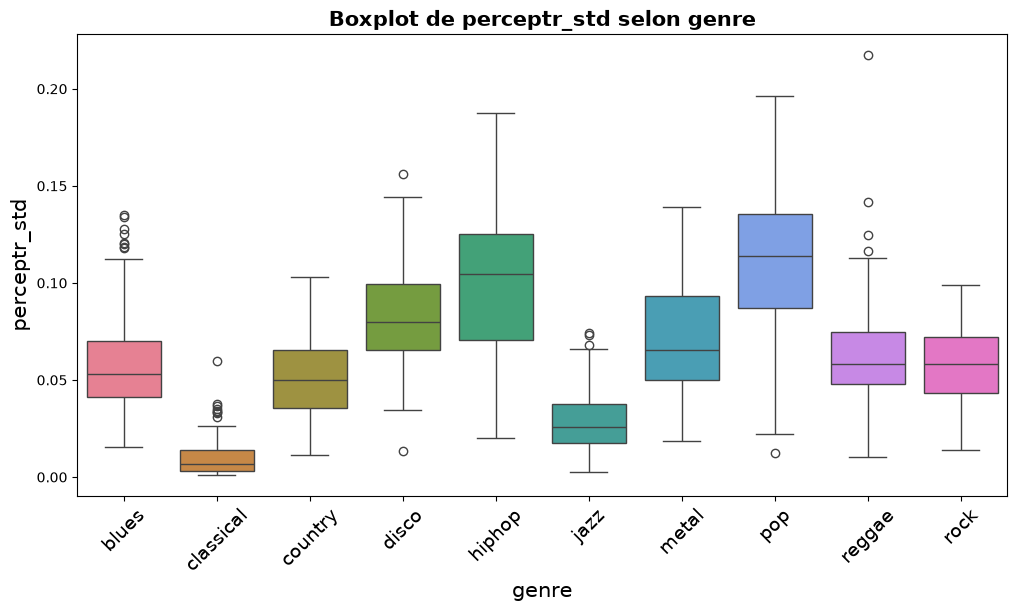

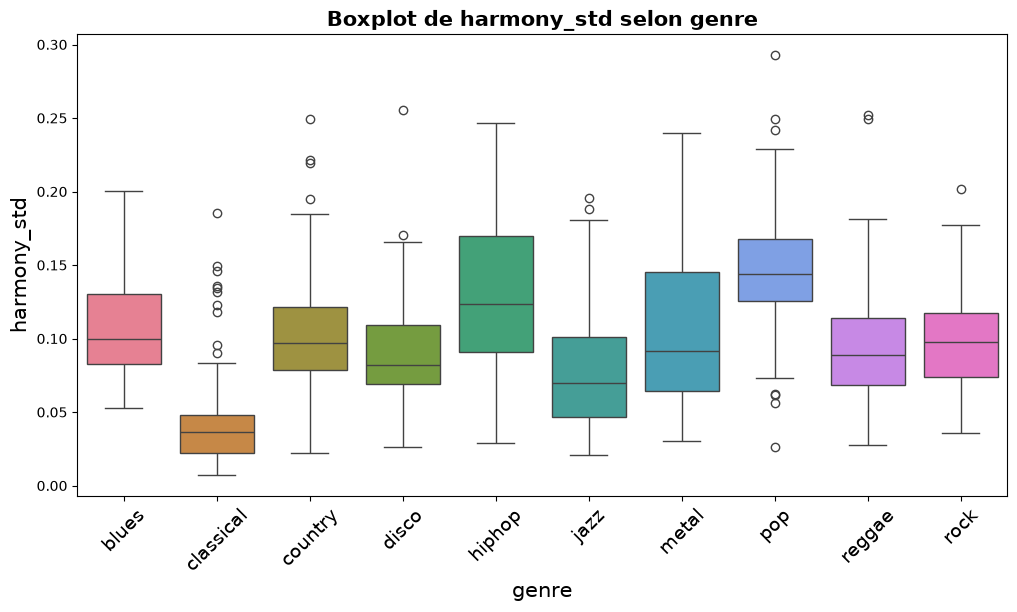

In [57]:
#echantillon de variables explicatives pour le boxplot
echantillon = [var for var in std_cols]
for i in echantillon:
    boxplot(variable_x = "genre",variable_y=i,data=df)


Avec ces graphiques , on observe des médianes qui sont globalement différentes.Ce qui souligne chez les variables/descripteurs en écart type  une possibilité de contribution à la séparation de genres musicaux.Toutefois,certaines variables chroma_ssf_std par exemple semblent ne pas avoir des différences assez significatives au niveau des médianes de certains genres : ceci témoigne de la ressemblanbce de certains morceau ainsi.


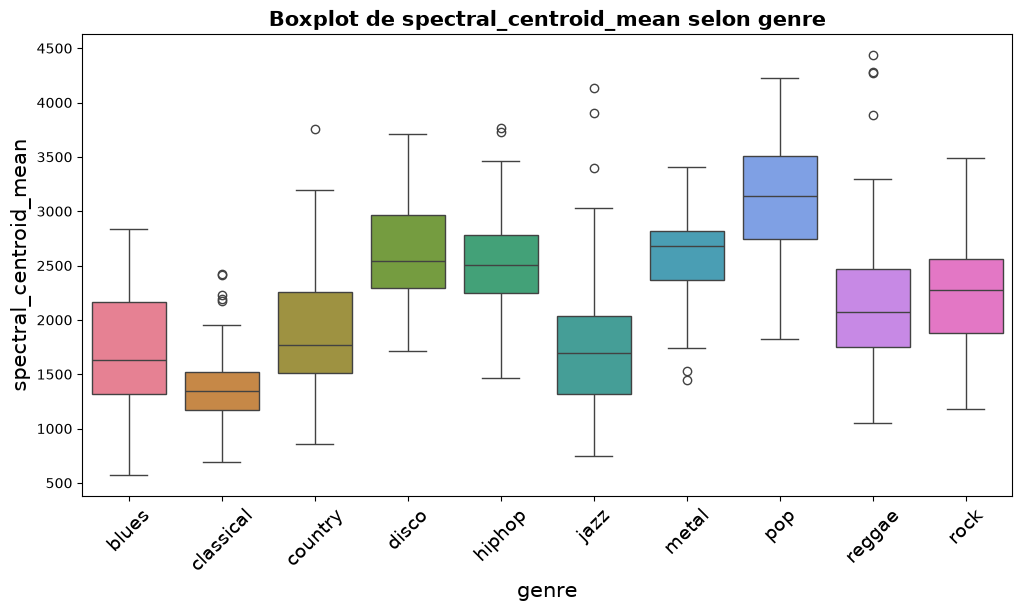

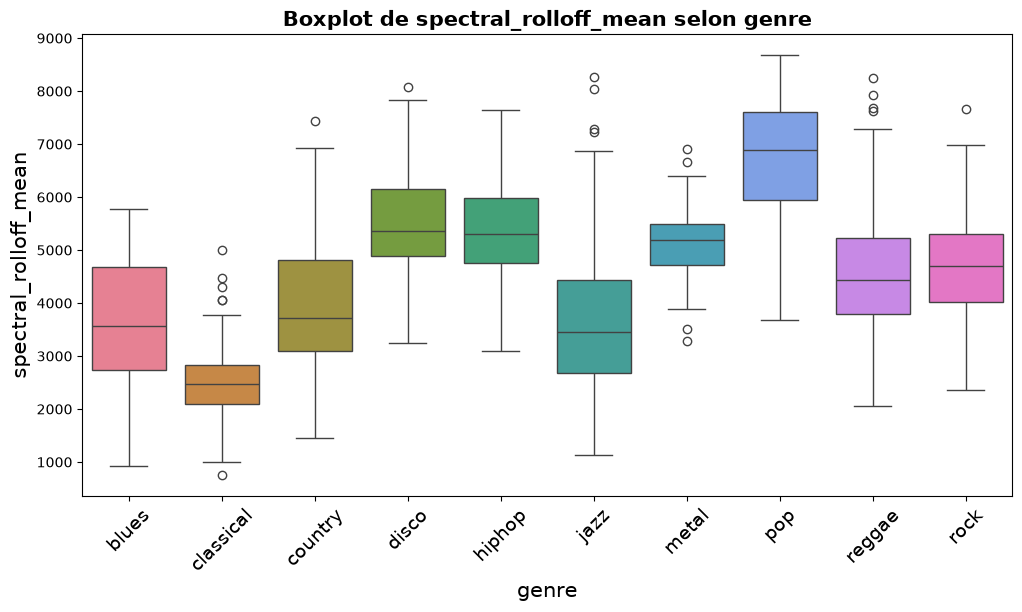

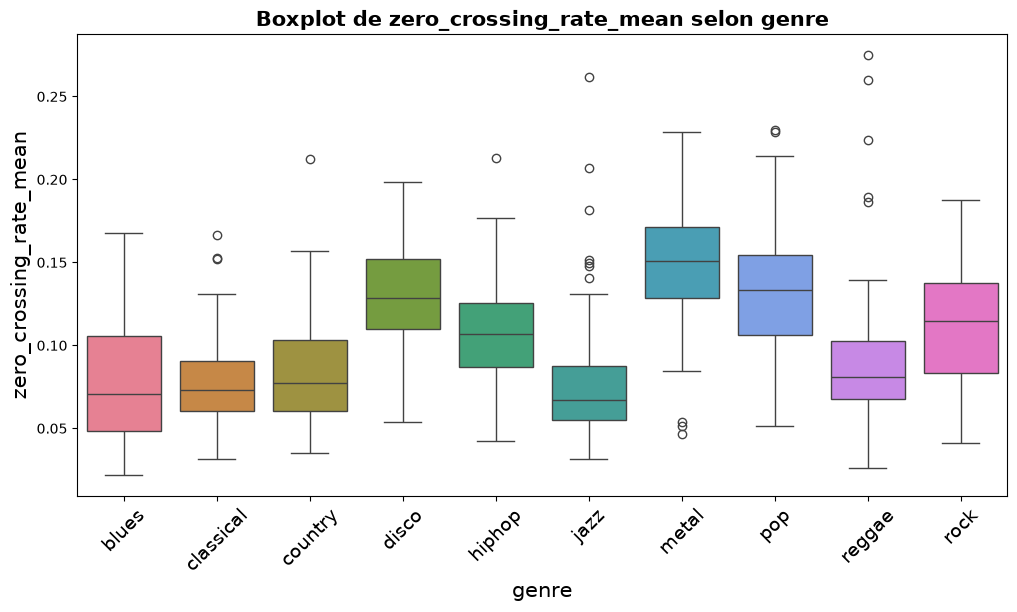

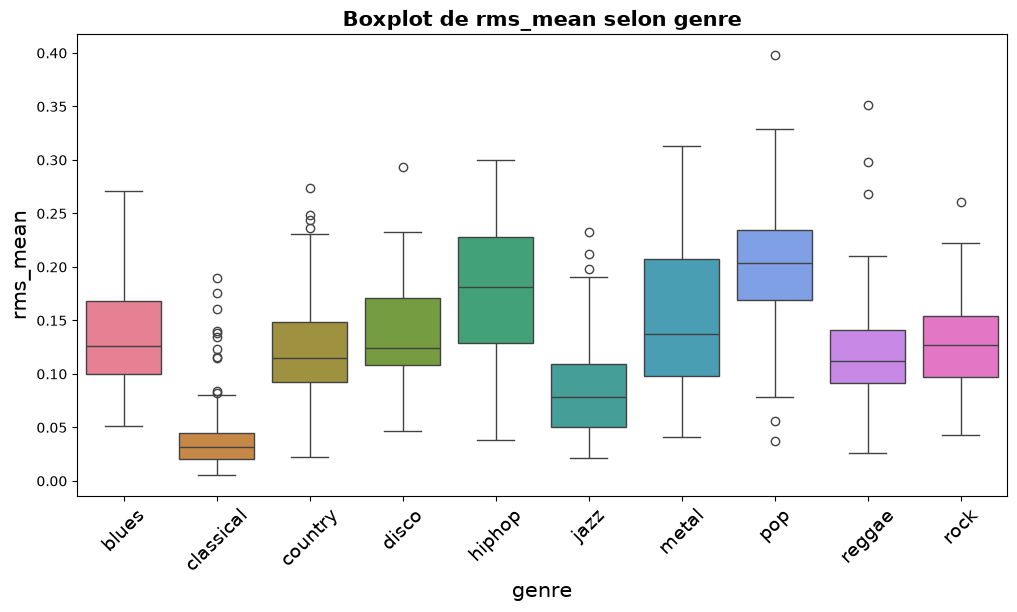

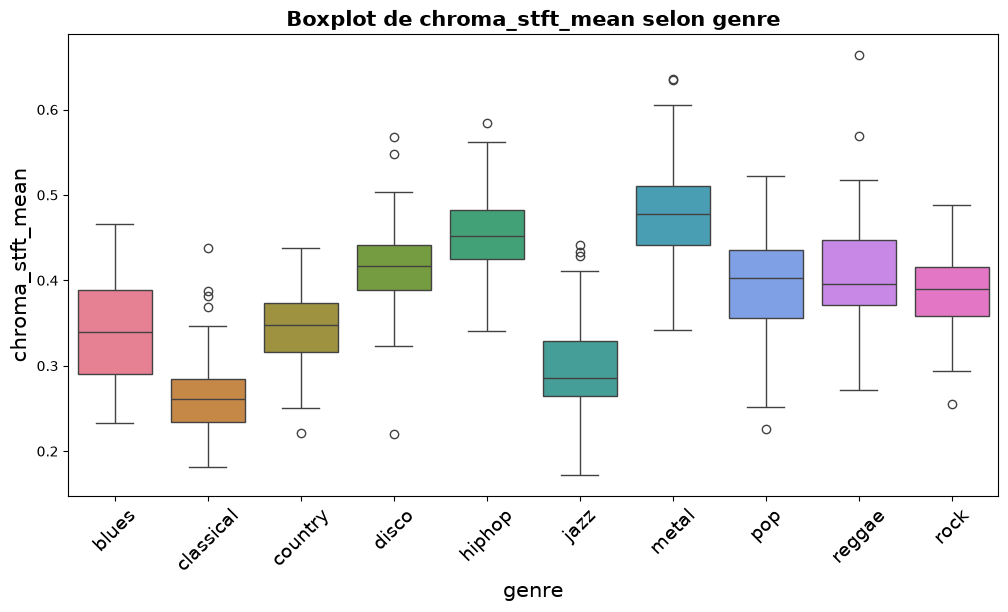

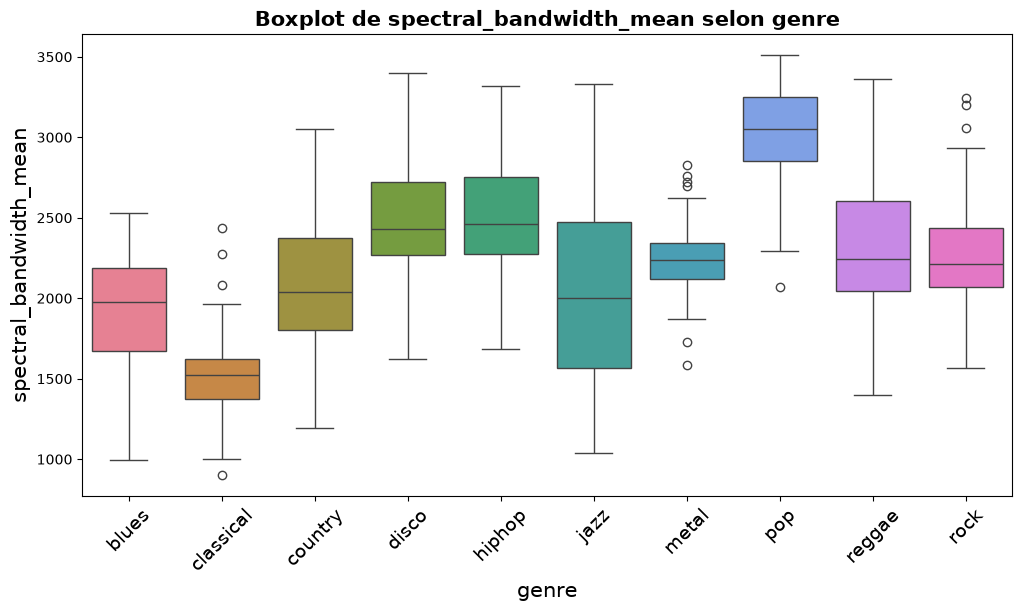

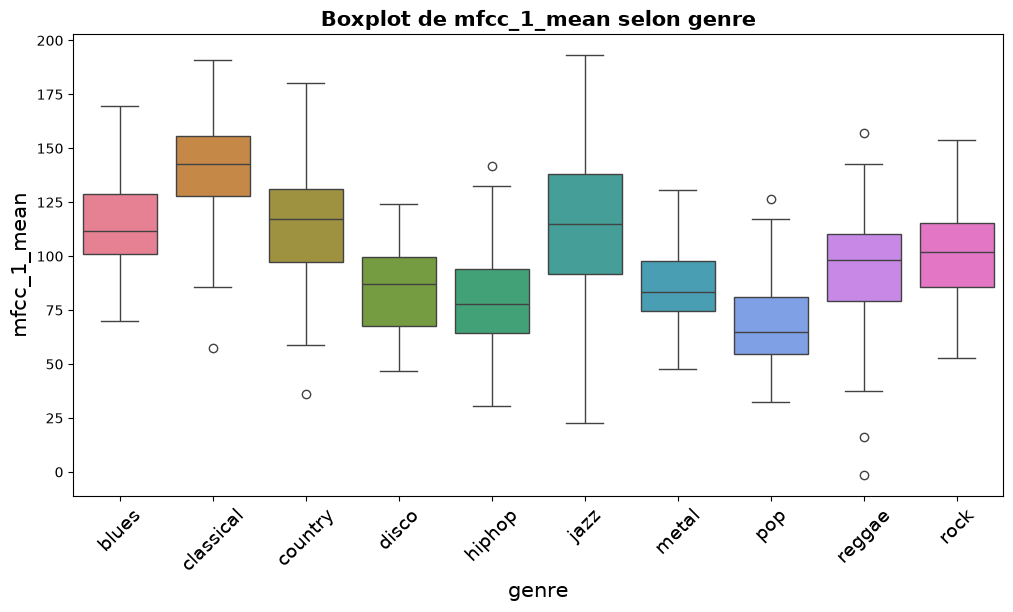

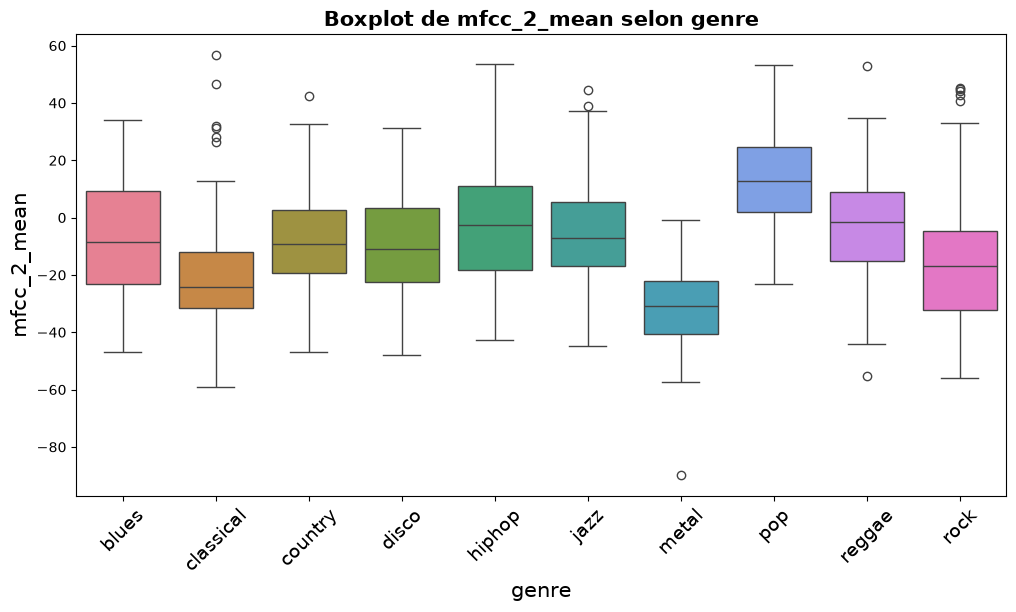

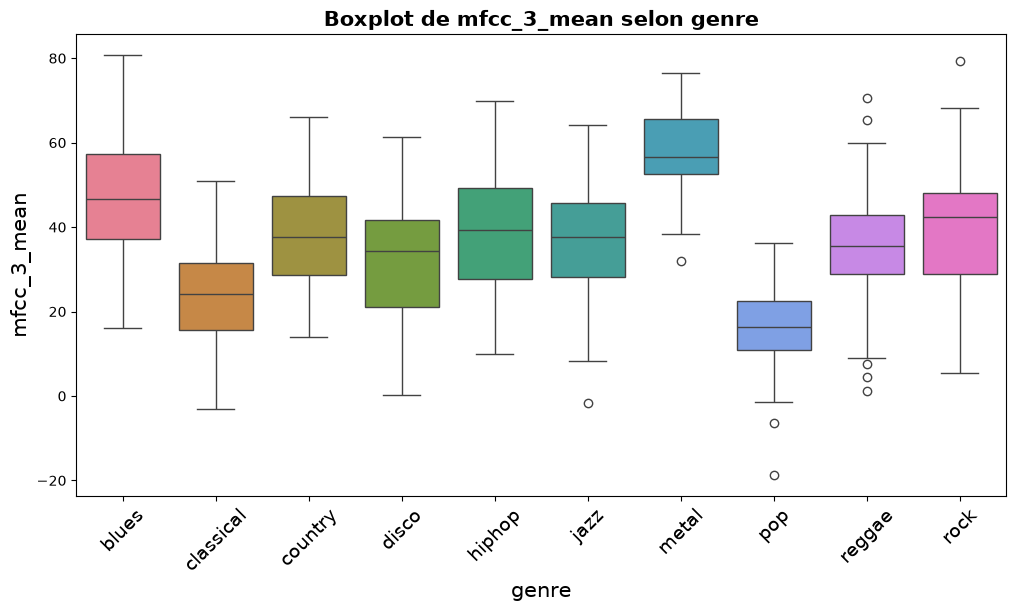

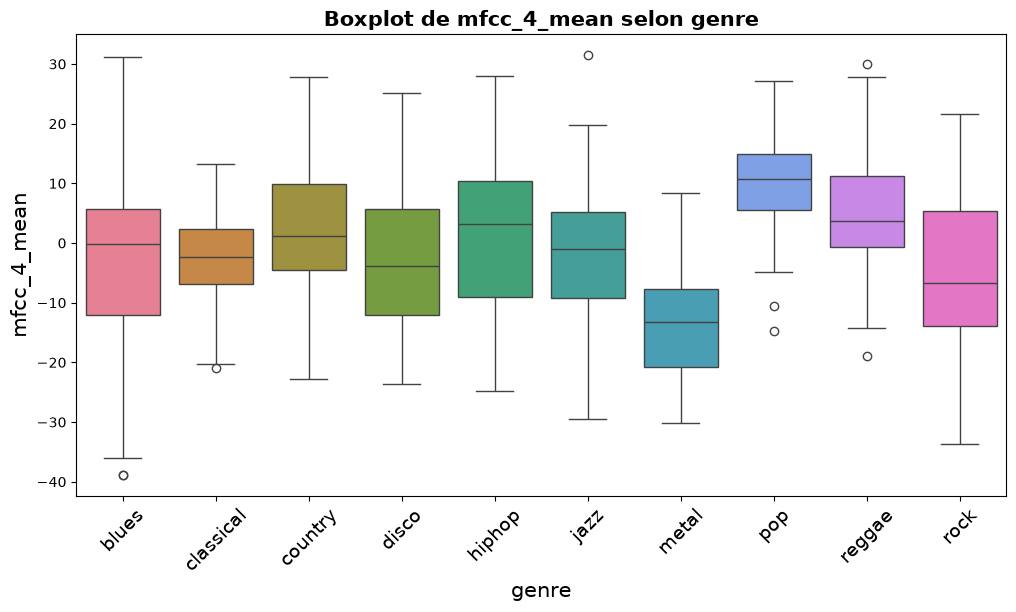

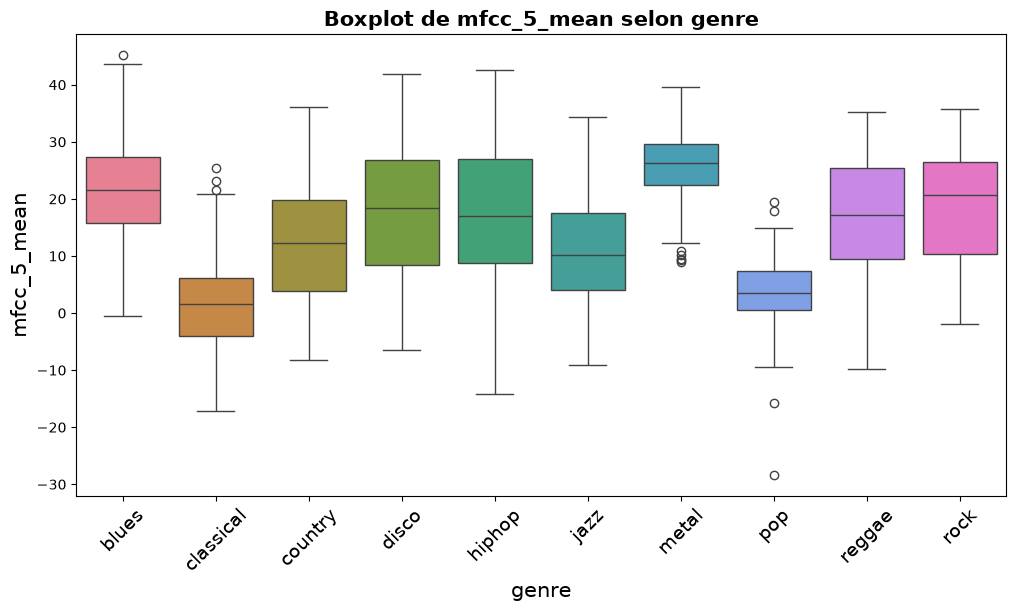

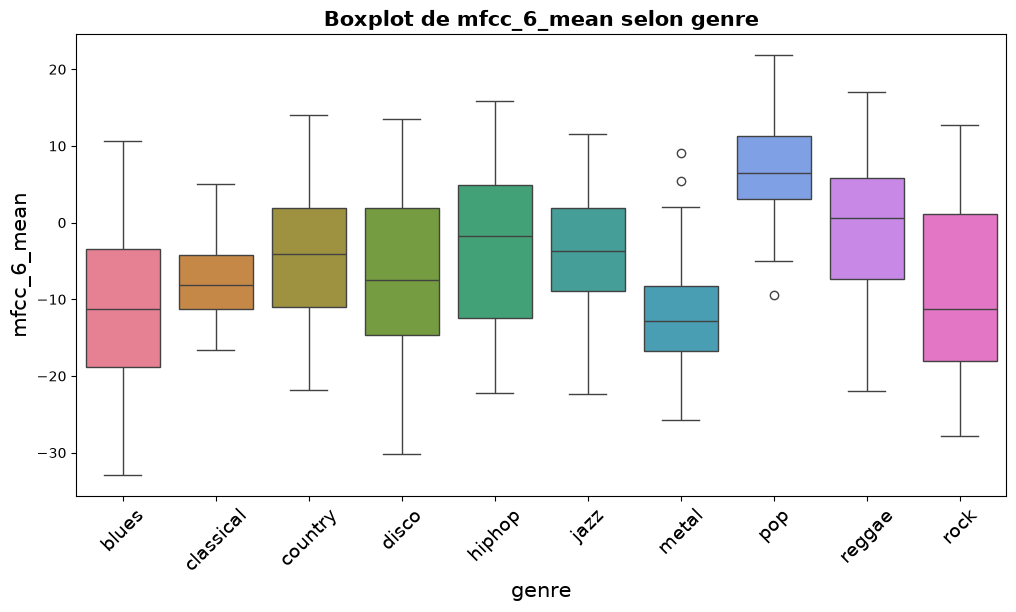

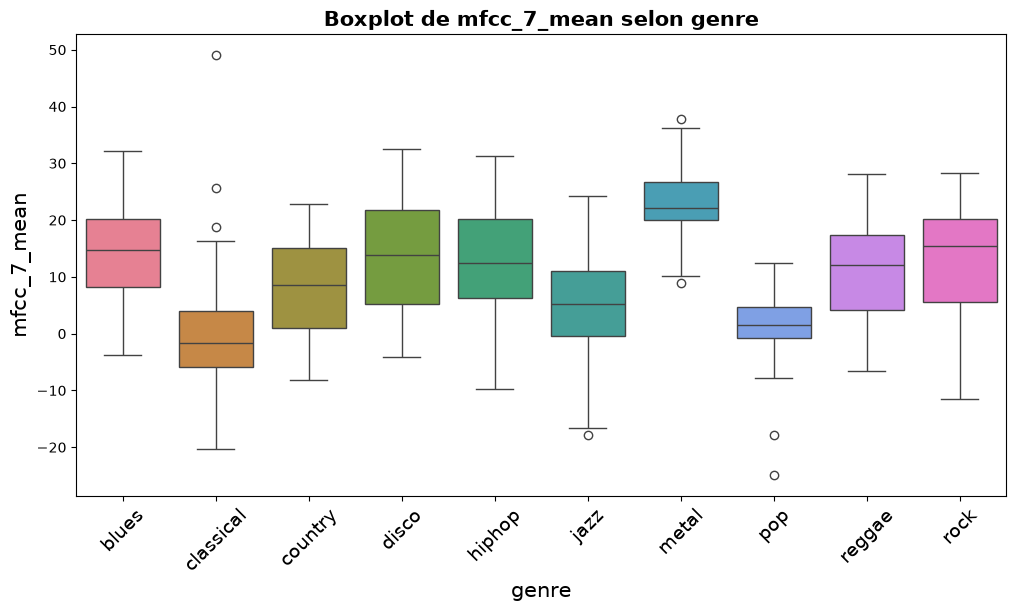

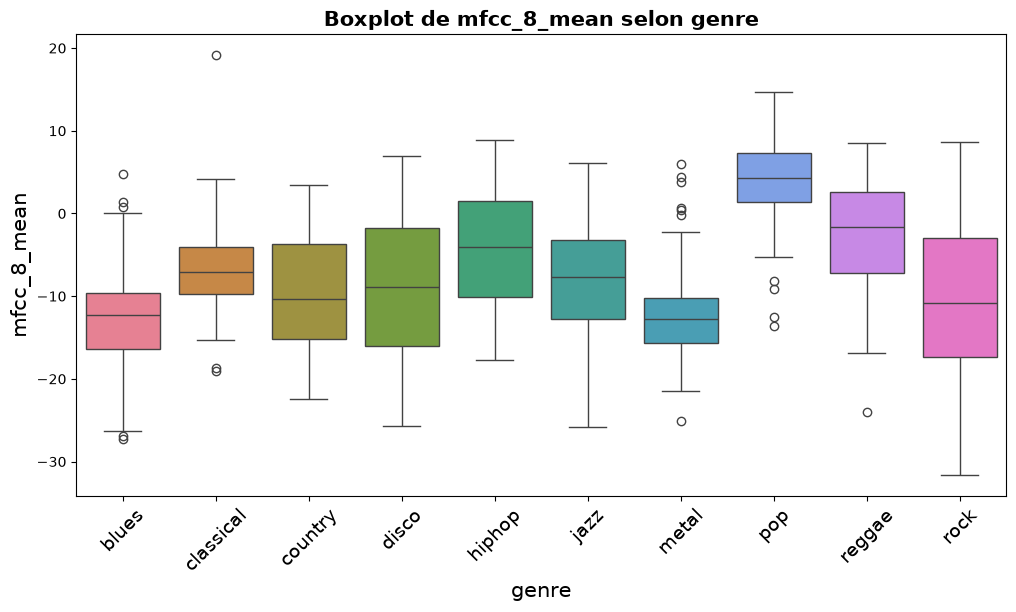

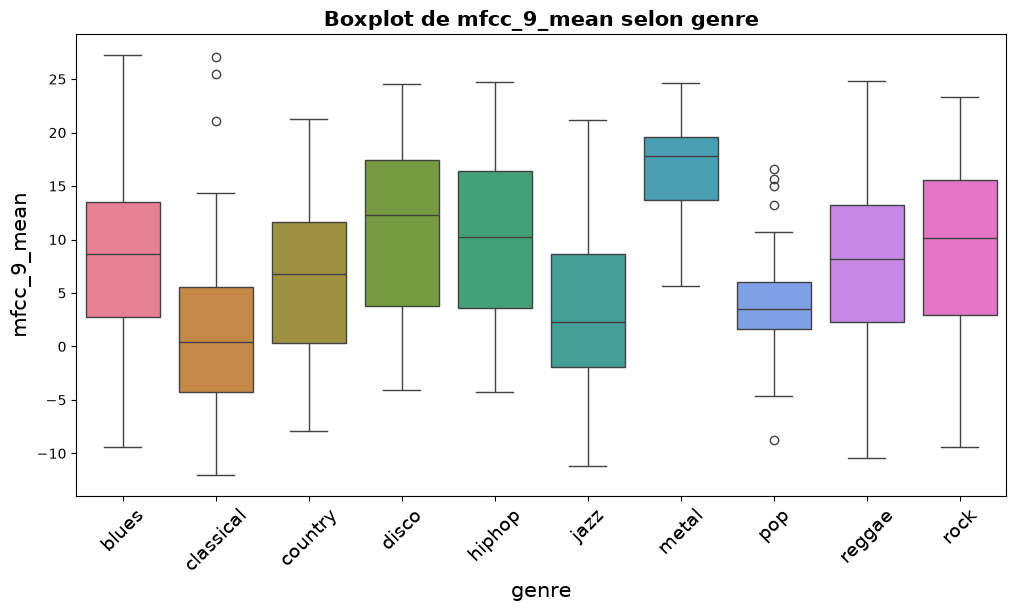

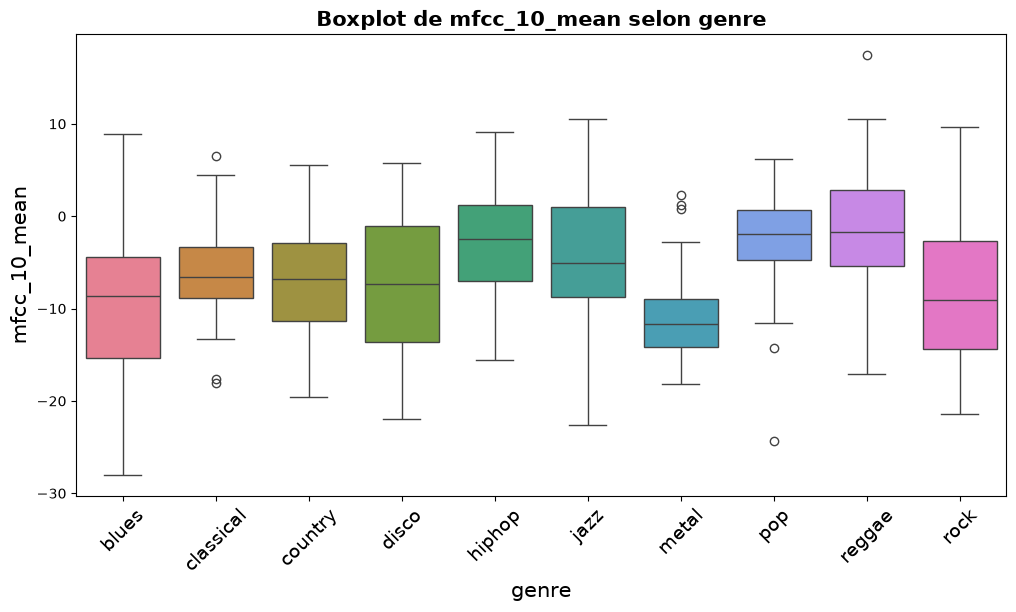

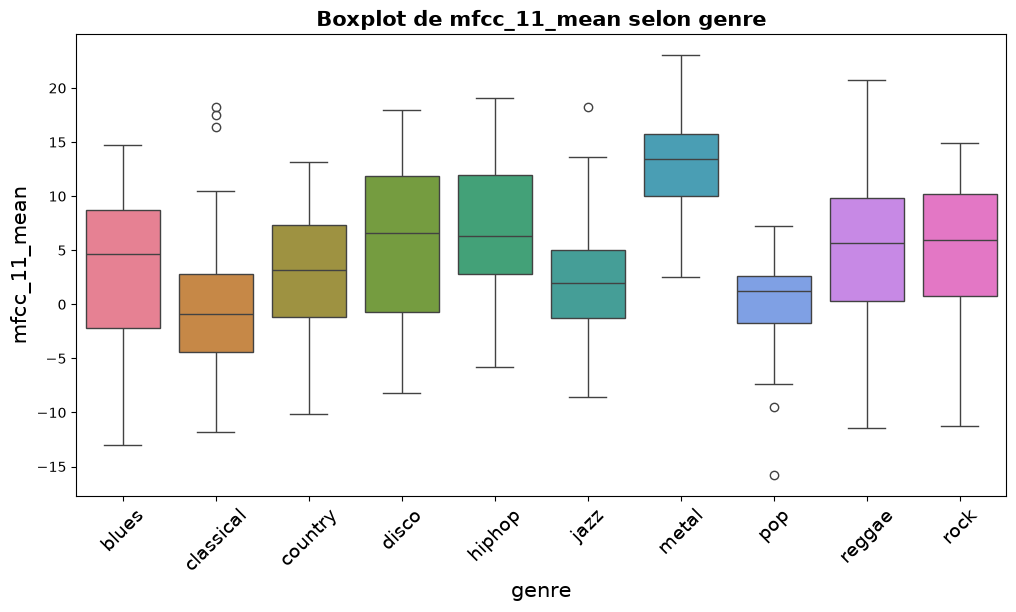

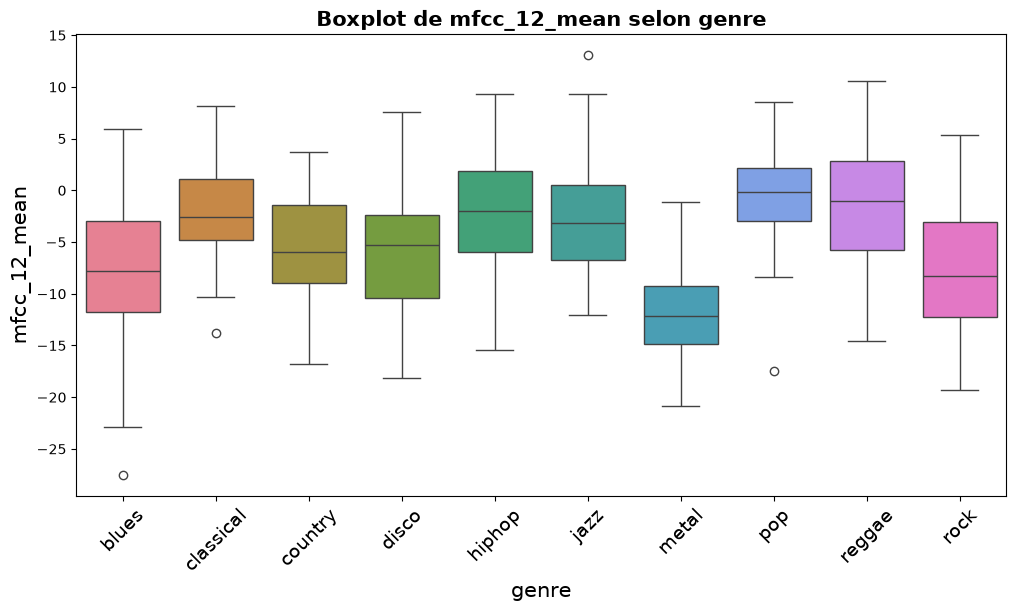

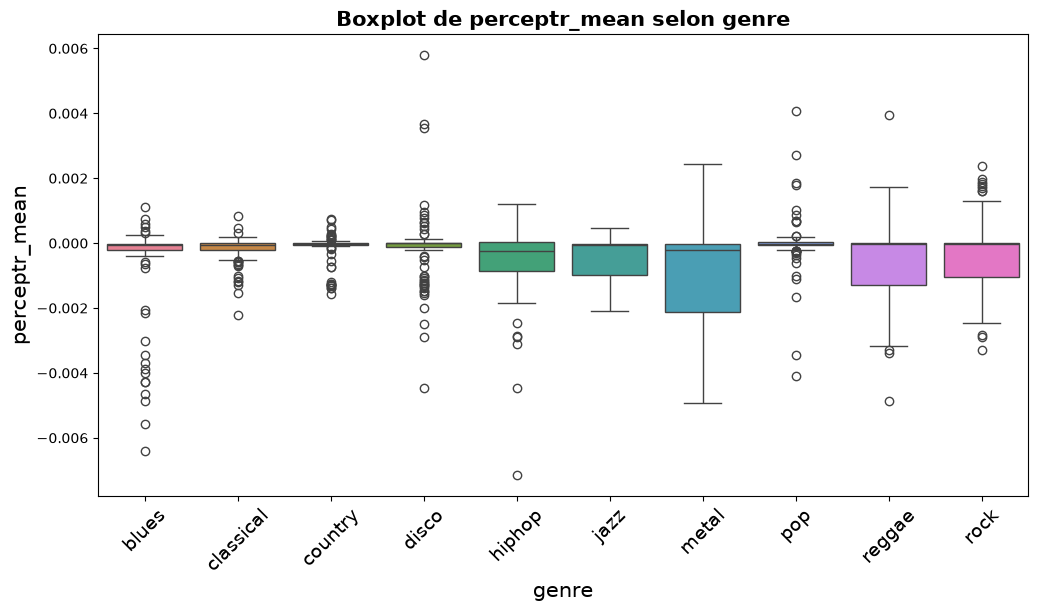

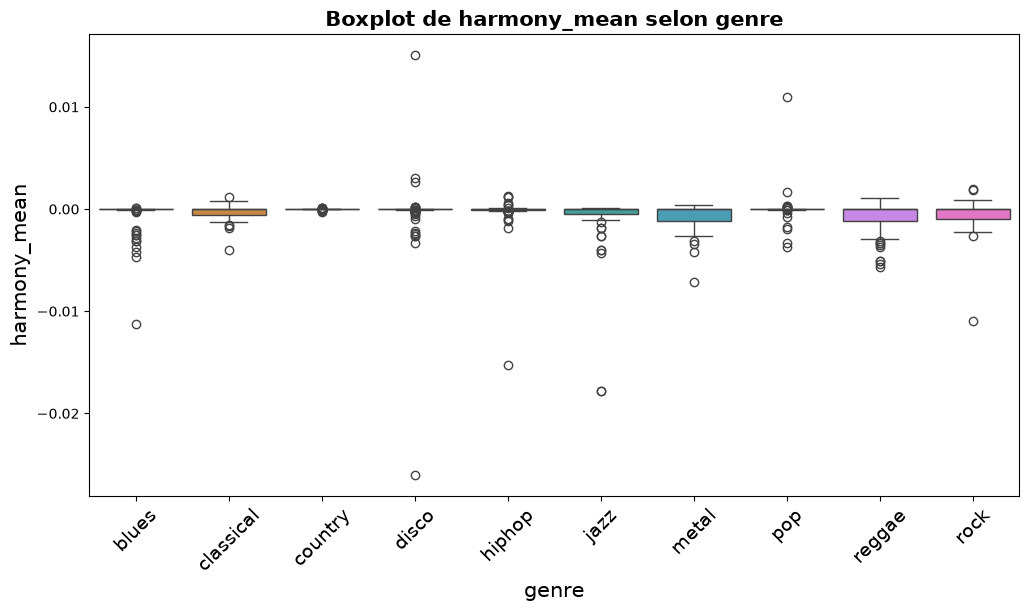

In [58]:
#echantillon de variables explicatives pour le boxplot
echantillon2 = [var for var in mean_cols ]
for i in echantillon2:
    boxplot(variable_x = "genre",variable_y=i,data=df)
    


D'après cette série de boxplots, on observe deux tendances principales.
Un premier groupe de descripteurs présente des médianes sensiblement
différentes selon les genres musicaux, ce qui suggère un potentiel 
pouvoir discriminatoire chez ces derniers.À l'inverse,on a harmony_mean  et perceptr_mean qui présentent des médianes très proches voire identiques d'un genre à l'autre.
Cette observation laisse à croire que, prise isolément, ces variables offrent
une capacité de séparation plus limitée ou quasi-inexistante entre les genres musicaux  bien que harmony_std et perceptr_mean soient discriminatrice.

In [59]:
X = df.drop(columns = ["nom_fichier","genre"])
y = df["genre"]
print(f'X.shape :{X.shape}')
print(f'y.shape :{y.shape}')


X.shape :(1000, 42)
y.shape :(1000,)


In [60]:
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler , StandardScaler, RobustScaler
from sklearn.model_selection import train_test_split

In [61]:
def encodage(y,y2):
    encoder = LabelEncoder()
    y= encoder.fit_transform(y)
    y2= encoder.transform(y2)
    return y,y2

In [62]:
def scaling(X,X2):
    scaler=StandardScaler()
    X= scaler.fit_transform(X)
    X2 = scaler.transform(X2)
    return X,X2

In [63]:
def preprocessing(X,X2,y,y2):
    y,y2= encodage(y,y2)
    X,X2= scaling(X,X2)
    return X,X2,y,y2

In [64]:
X_train , X_test , y_train , y_test = train_test_split(X,y,test_size=0.2,
                                     random_state=42,stratify=y)

In [65]:
X_train_scaled , X_test_scaled , y_train_encoded , y_test_encoded = preprocessing(X_train ,
                                 X_test ,y_train , y_test)

In [66]:
print(X_train_scaled.shape,y_train_encoded.shape)
print(X_test_scaled.shape,y_test_encoded.shape)

(800, 42) (800,)
(200, 42) (200,)


In [67]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score,classification_report,confusion_matrix,accuracy_score,recall_score

In [68]:

XGB_model = XGBClassifier()
SVC_model = SVC()
RandomF_model = RandomForestClassifier(random_state = 42)
logistic_model = LogisticRegression()
DecisionTree_model =DecisionTreeClassifier()
KNN = KNeighborsClassifier(n_neighbors=8)


In [69]:
modeles = {"LogisticRegression"         :logistic_model,
            "DecisionTreeClassifier"    :DecisionTree_model,
                "RandomForestClassifier":RandomF_model,
                "SVC"                   : SVC_model,
                "KNeighborsClassifier"  :KNN,
           "XGBClassifier"              : XGB_model}

In [70]:
def evaluation(model,X_train,y_train,X_test,y_test):
    model.fit(X_train,y_train)
    y_pred = model.predict(X_test)
    score = f1_score(y_test,y_pred,average='macro')
    print("f1_score:",score)
    print("accuracy_score:",accuracy_score(y_test,y_pred))

In [71]:
for name,model in modeles.items():
    print(name,"...")
    evaluation(model,X_train_scaled,y_train_encoded,X_test_scaled,y_test_encoded)


LogisticRegression ...
f1_score: 0.6957732334776483
accuracy_score: 0.7
DecisionTreeClassifier ...
f1_score: 0.5679863643014561
accuracy_score: 0.565
RandomForestClassifier ...
f1_score: 0.6816536960584609
accuracy_score: 0.69
SVC ...
f1_score: 0.7221901281754403
accuracy_score: 0.72
KNeighborsClassifier ...
f1_score: 0.714034045859284
accuracy_score: 0.715
XGBClassifier ...
f1_score: 0.6862773665641801
accuracy_score: 0.695


Après cette évaluation sans aucun traitement particulier des variables,
les modèles les plus performants sont : KNN  ,SVC , LogisticRegression.



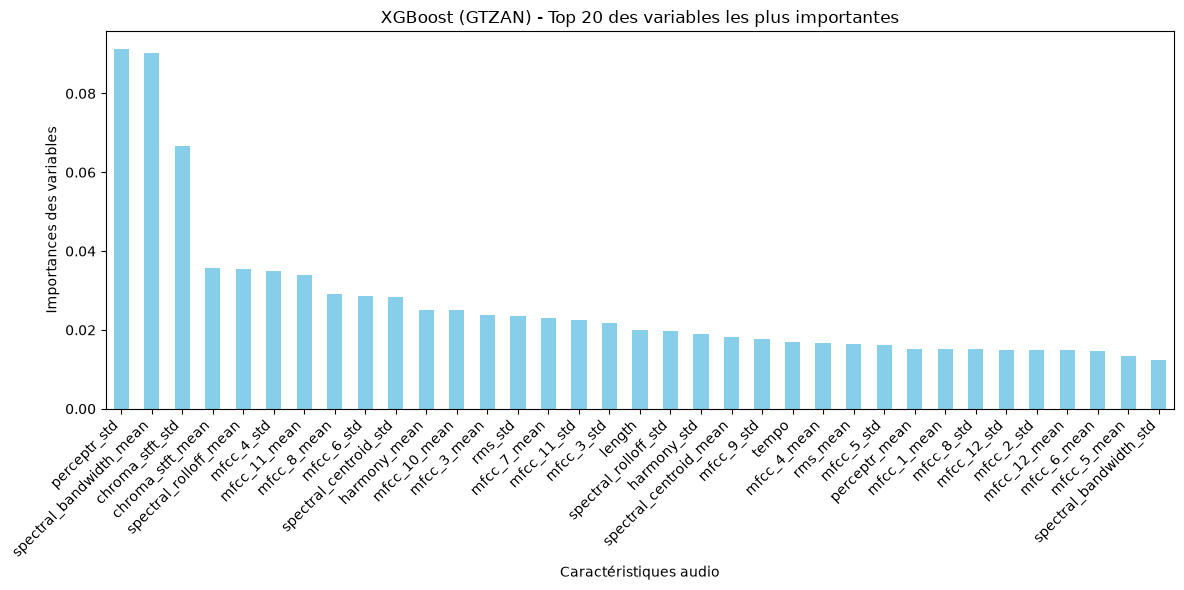

In [72]:
# Extraction des variables importantes triées par ordre décroissant pour XgbClassifier
xgb_importances = pd.Series(XGB_model.feature_importances_, 
        index=df.drop(columns=["nom_fichier","genre"]).columns)
# On trie et 35 premières variables importantes pour Xgbosst bien entendu
xgb_importances_trie = xgb_importances.sort_values(ascending=False).head(35)

plt.figure(figsize=(12, 6))
xgb_importances_trie.plot(kind="bar", color="skyblue") 

plt.title("XGBoost (GTZAN) - Top 20 des variables les plus importantes")
plt.ylabel("Importances des variables") 
plt.xlabel("Caractéristiques audio")
# Rotation à 45 degrés des noms des variables pour éviter qu'ils ne se chevauchent
plt.xticks(rotation=45, ha="right") 
plt.tight_layout()
plt.show()



In [73]:
alpha=35 # on garde les alpha descripteurs les plus importants
top_descripteurs = xgb_importances_trie.index[:alpha].tolist()

In [74]:
# CONVERTION EN DF POUR LA SEPARATION 
X_train = pd.DataFrame(X_train,columns=X.columns)
X_test = pd.DataFrame(X_test,columns=X.columns)


In [75]:

X_train_reduit = X_train[top_descripteurs]
X_test_reduit  = X_test[top_descripteurs]


In [76]:
X_train_reduit, X_test_reduit = scaling(X_train_reduit,X_test_reduit)

In [77]:
for name,model in modeles.items():
    print(name,"...")
    evaluation(model,X_train_reduit,y_train_encoded,X_test_reduit,y_test_encoded)

LogisticRegression ...
f1_score: 0.6732513486633697
accuracy_score: 0.68
DecisionTreeClassifier ...
f1_score: 0.548758073048892
accuracy_score: 0.545
RandomForestClassifier ...
f1_score: 0.6891208251481687
accuracy_score: 0.695
SVC ...
f1_score: 0.760069647014448
accuracy_score: 0.76
KNeighborsClassifier ...
f1_score: 0.7178715281722399
accuracy_score: 0.72
XGBClassifier ...
f1_score: 0.73115130464464
accuracy_score: 0.74


La selection des 35 variables  les plus importantes 
pour le modèle de XGBOOST  a été globalement favorable
pour tous ces  modèles.



# Recherche en grille

In [78]:

def recherche_grille(model, param, X_train_scaled, y_train_encoded,X_test_scaled,y_test_encoded):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    grid = GridSearchCV(estimator=model,param_grid=param,
    cv=cv,scoring='f1_macro',n_jobs=-1,verbose=0)
    grid.fit(X_train_scaled, y_train_encoded)
    print("Meilleur score :", grid.best_score_)
    print("Meilleurs paramètres :", grid.best_params_)
    print("test :", grid.score(X_test_scaled, y_test_encoded)) 
    return grid.best_estimator_


In [79]:
logistic_reg_param = {"C":[0.001,0.01,0.1,1,10,100],"solver":["lbfgs","liblinear"],
                      "penalty":["l2"],"max_iter":[200,500,750,850,1000]}
svc_param = {"C":[0.1,1,3,10,30,50,100],"kernel":["rbf"],
    "gamma":[0.001,0.003,0.01,0.03,0.1,"scale","auto"]}

KNN_param = {"n_neighbors":[3,5,7,8,9,11,13],
    "weights":["uniform","distance"],"p":[1,2]}



xgboost_param = {
    'n_estimators':     [200, 400],
    'max_depth':        [3, 5],
    'learning_rate':    [0.05, 0.1],
    'subsample':        [0.7, 1.0],
    'colsample_bytree': [0.5, 0.8],
}



In [80]:
#SVC
BestSVC=recherche_grille(modeles["SVC"], svc_param, X_train_scaled, y_train_encoded,X_test_scaled,y_test_encoded)

Meilleur score : 0.7478231387351326
Meilleurs paramètres : {'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}
test : 0.7222059644324736


In [81]:
#KNN
BestKNN = recherche_grille(modeles["KNeighborsClassifier"], KNN_param, X_train_scaled, y_train_encoded,X_test_scaled,y_test_encoded)


Meilleur score : 0.6712602694853629
Meilleurs paramètres : {'n_neighbors': 7, 'p': 2, 'weights': 'distance'}
test : 0.7461261318726297


In [40]:

BestXGB = recherche_grille(modeles["XGBClassifier"], xgboost_param, X_train_scaled, y_train_encoded,X_test_scaled,y_test_encoded)


Meilleur score : 0.7365030588160467
Meilleurs paramètres : {'colsample_bytree': 0.5, 'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 400, 'subsample': 0.7}
test : 0.7286268140106704


In [82]:
print("BestSVC")
evaluation(BestSVC,X_train_scaled,y_train_encoded,X_test_scaled,y_test_encoded)

print("BestXGB")
evaluation(BestXGB,X_train_scaled,y_train_encoded,X_test_scaled,y_test_encoded)

print("BestKNN")
evaluation(BestKNN,X_train_scaled,y_train_encoded,X_test_scaled,y_test_encoded)

BestSVC
f1_score: 0.7222059644324736
accuracy_score: 0.725
BestXGB
f1_score: 0.7286268140106704
accuracy_score: 0.73
BestKNN
f1_score: 0.7461261318726297
accuracy_score: 0.745


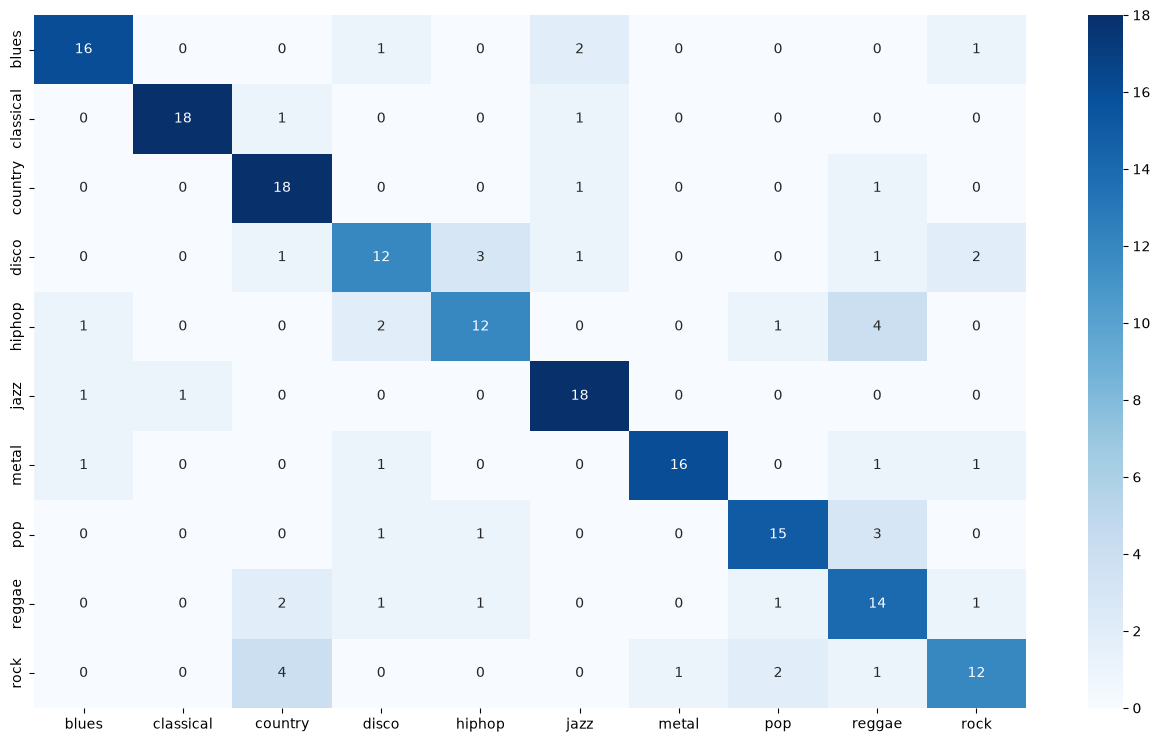

In [83]:

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train[top_descripteurs])   # fit uniquement  sur le train
X_test_scaled  = scaler.transform(X_test[top_descripteurs])

# entraînement du modèle sur X_train_scaled, etc.

BestSVC.fit(X_train_scaled,y_train_encoded)
y_pred = BestSVC.predict(X_test_scaled)
#score = f1_score(y_test,y_pred,average='macro')
confusion_matr = confusion_matrix(y_test_encoded, y_pred) 
plt.figure(figsize = (16, 9))
sns.heatmap(confusion_matr, cmap="Blues", annot=True, 
            xticklabels = ["blues", "classical", "country", "disco", "hiphop", "jazz", "metal", "pop", "reggae", "rock"],
           yticklabels=["blues", "classical", "country", "disco", "hiphop", "jazz", "metal", "pop", "reggae", "rock"]);
#plt.savefig("ConfusionMatrix.png")

In [85]:
# Courbe d'apprentissage 
from sklearn.model_selection import learning_curve
def learningCurve(model,X_train_scaled,y_train_scaled):
    N , train_score , test_score = learning_curve(model , X=X_train_scaled ,y=y_train_scaled , cv = 5 ,train_sizes = np.linspace(0.1 , 1.0 ,10) , scoring = "f1_macro") 
    plt.plot(N , train_score.mean(axis = 1),label = "train_score")
    plt.xlabel("train_data") 
    plt.plot(N , test_score.mean(axis = 1), label = "test_score")
    plt.ylabel(" les scores" ) 
    plt.legend()
    plt.grid(True)
    plt.show()



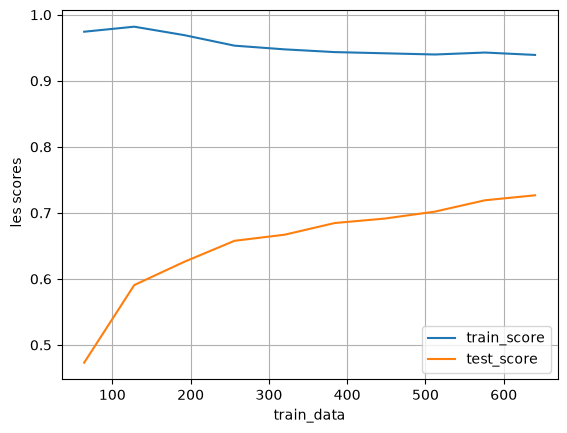

In [86]:
learningCurve(BestSVC,X_train_scaled,y_train_encoded)


seul SVC présente une courbe d'apprentisage pour laquelle le train score et le test score tendent 
a se rencontrer ,échappant ainsi au surapprentissage observé chez les 2 autres modèles.Toutefois , 
il faut à notre modèle plus de données pour mieux apprendre.

In [87]:
from features_extraction import extraire_features
import pandas as pd 

le = LabelEncoder().fit(y_train)

def prediction(fichier, model, scaler=scaler,le=le):

    features = extraire_features(fichier)
    df = pd.DataFrame([features])
    X_a_predire = df[top_descripteurs]          # même colonnes, même ordre qu'à l'entraînement
    X_a_predire = scaler.transform(X_a_predire)  # transform seulement, jamais fit
    print("classe predite:",model.predict(X_a_predire),le.inverse_transform(model.predict(X_a_predire)))
    return model.predict(X_a_predire)




In [ ]:
# Prédiction avec un son déja vu 
prediction(r"C:\Users\ADMIN\gtzanProject\audio_data\reggae\reggae.00008.wav", BestSVC, scaler)


classe predite: [8] ['reggae']


array([8])

In [100]:
# prédiction avec des exemplaires de son (30 sec au min) jamais vu par bestSVC
import os 
dossier_racine = r"C:\Users\ADMIN\Desktop\predict_data"
for racine, sous_dossiers, fichiers in os.walk(dossier_racine):
    genre_reel = os.path.basename(racine)
    for chanson in fichiers:
        if not chanson.lower().endswith(('.wav', '.mp3', '.flac', '.m4a')):
            continue
        chemin = os.path.join(racine, chanson)   # racine = dossier courant parcouru
        print("Genre réel:",genre_reel)
        try:
            prediction(chemin, BestSVC)
        except KeyError:
            print("Genre introuvable")

        except Exception as e:
            print(f"  -> Erreur sur {chemin}: {str(e)}")


Genre réel: blues
classe predite: [9] ['rock']
Genre réel: classical
classe predite: [1] ['classical']
Genre réel: disco
classe predite: [7] ['pop']
Genre réel: hip-pop
classe predite: [3] ['disco']
Genre réel: jazz
classe predite: [9] ['rock']
Genre réel: pop
classe predite: [4] ['hiphop']
Genre réel: rap
Genre introuvable
Genre réel: reggae
classe predite: [8] ['reggae']
Genre réel: rock
classe predite: [4] ['hiphop']
